# 02 · Two ways to guess Apartment or Villa

**The problem.** Suppose a row is missing its type. To understand two
methods, we’ll use apartment and villa sizes with known labels.

**Why these methods.** KNN guesses by looking at the closest examples.
SVM learns a dividing line. Both produce a class label.

We select eight examples with a clear gap between the groups. That makes
the methods easy to see. Real apartment and villa sizes can overlap.
Run this as a short preview after notebook 01.

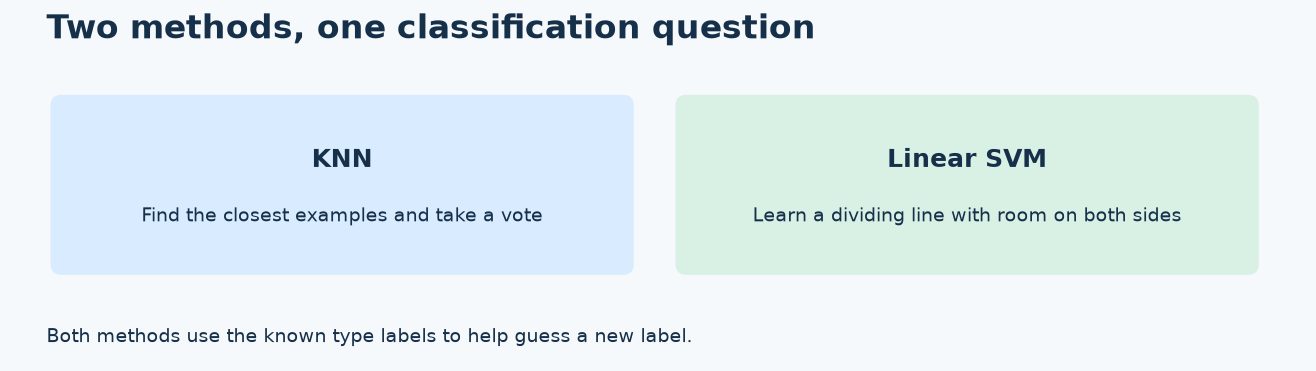

## 1 · Show the known examples

**What we’re doing.** Take four apartments and four villas from the course file.

**Why we’re doing it.** These are the rows with answers. We will use them to guess a type for another size.

**What to look for.** Each row has a size and a label. Find the gap between the largest apartment and the smallest villa.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from pathlib import Path

current_folder = Path.cwd()
data_folder = next(
    (folder / "data" for folder in (current_folder, *current_folder.parents)
     if (folder / "data" / "property_valuations.csv").is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["valuation_date", "property_type", "emirate", "size_sqft", "valuation_aed"]
properties = pd.read_csv(data_folder / "property_valuations.csv", usecols=columns, parse_dates=["valuation_date"])
dubai = properties[properties["emirate"] == "Dubai"]
dubai = dubai.query("size_sqft > 0 and valuation_aed > 0")
apartments = dubai[dubai["property_type"] == "Apartment"]

small = apartments[apartments["size_sqft"].between(700, 1400)].sample(4, random_state=42)
large = dubai[(dubai["property_type"] == "Villa") & dubai["size_sqft"].between(2500, 4100)].sample(4, random_state=42)
examples = pd.concat([small, large]).sort_values("size_sqft")
examples[["size_sqft", "property_type"]]

,size_sqft,property_type
32821,831.0,Apartment
65253,956.0,Apartment
69804,1030.0,Apartment
153753,1385.0,Apartment
21401,2755.0,Villa
182436,3082.0,Villa
137911,3174.0,Villa
144212,3224.0,Villa


## 2 · See the three nearest neighbours

**What we’re doing.** Find the three example sizes closest to 2,000 square feet. Count their labels.

**Why we’re doing it.** KNN means k-nearest neighbours. Here k is three, the number of examples that get to vote.

**What to look for.** Two neighbours are apartments and one is a villa. The majority vote is Apartment.

In [2]:
size_to_check = 2000
nearby = examples[["size_sqft", "property_type"]].copy()
nearby["distance_in_sqft"] = (nearby["size_sqft"] - size_to_check).abs()
nearest = nearby.nsmallest(3, "distance_in_sqft")
display(nearest)
display(nearest["property_type"].value_counts())

,size_sqft,property_type,distance_in_sqft
153753,1385.0,Apartment,615.0
21401,2755.0,Villa,755.0
69804,1030.0,Apartment,970.0


property_type
Apartment    2
Villa        1
Name: count, dtype: int64

### See the neighbours vote

Each bar shows how far one of the three closest examples is from
2,000 square feet. The two Apartment labels win the vote.

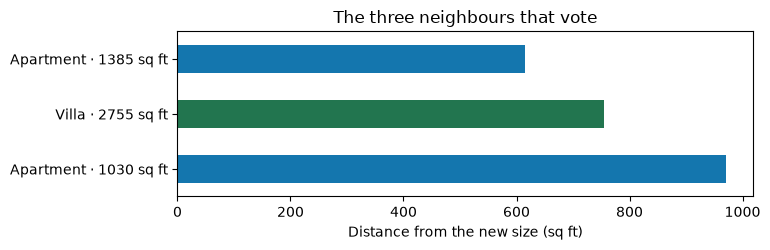

In [3]:
names = nearest["property_type"] + " · " + nearest["size_sqft"].round().astype(int).astype(str) + " sq ft"
colors = nearest["property_type"].map({"Apartment": "#1476ae", "Villa": "#22754f"})
ax = nearest.set_index(names)["distance_in_sqft"].plot.barh(figsize=(7.8, 2.6), color=colors)
ax.invert_yaxis()
ax.set(title="The three neighbours that vote", xlabel="Distance from the new size (sq ft)", ylabel="")
plt.tight_layout()
plt.show()

## 3 · Ask KNN to make the same guess

**What we’re doing.** Give the sizes and known types to the KNN tool. Ask it to predict the type for 2,000 square feet.

**Why we’re doing it.** This tool does the same neighbour search and vote we just did. Use it when closeness between examples has a useful meaning.

**What to look for.** KNN returns Apartment. The input remains a table with a size column, even for one property.

In [4]:
sizes = examples[["size_sqft"]] / 1000
labels = examples["property_type"]
new_property = pd.DataFrame({"size_sqft": [size_to_check]}) / 1000

neighbours = KNeighborsClassifier(n_neighbors=3)
neighbours.fit(sizes, labels)
print("KNN guess:", neighbours.predict(new_property)[0])

KNN guess: Apartment


## 4 · Ask SVM to find a dividing line

**What we’re doing.** Train a linear support vector machine on the same examples and make a guess for the same size.

**Why we’re doing it.** With groups like these, SVM looks for a dividing line with the widest gap from the closest examples on each side. New sizes are classified by which side they are on.

**What to look for.** The linear SVM also predicts Apartment at 2,000 square feet. The next chart shows its dividing line.

In [5]:
divider = SVC(kernel="linear")
divider.fit(sizes, labels)
print("SVM guess:", divider.predict(new_property)[0])

SVM guess: Apartment


## 5 · See the dividing line

**What we’re doing.** Plot the training examples and the line found by SVM.

**Why we’re doing it.** The closest examples set the edges of the gap here. These examples are called support vectors.

**What to look for.** The dashed line is near 2,070 square feet. The amber marker to its left shows the property we are guessing for.

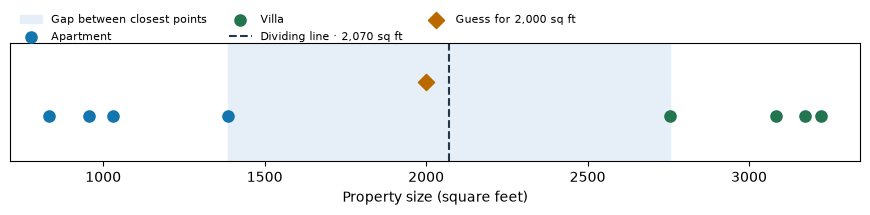

In [6]:
# Prepared chart. Convert the numbers back to square feet for the axis.
boundary = -divider.intercept_[0] / divider.coef_[0, 0] * 1000
edge_sizes = divider.support_vectors_.ravel() * 1000
fig, ax = plt.subplots(figsize=(8.8, 2.5))
ax.axvspan(edge_sizes.min(), edge_sizes.max(), color="#e6eff7", label="Gap between closest points")
for label, color in [("Apartment", "#1476ae"), ("Villa", "#22754f")]:
    points = examples.loc[examples["property_type"] == label, "size_sqft"]
    ax.scatter(points, [0] * len(points), s=65, color=color, label=label, zorder=3)
ax.axvline(boundary, color="#26364a", ls="--", label=f"Dividing line · {boundary:,.0f} sq ft")
ax.scatter([size_to_check], [.16], marker="D", s=68, color="#ba6900", label=f"Guess for {size_to_check:,} sq ft")
ax.set(xlabel="Property size (square feet)", yticks=[], ylim=(-.22, .35))
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.33), ncol=3, frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**About the size units.** Both methods see the numbers in thousands of
square feet. For example, 2,000 becomes 2. When a model uses several
inputs, their units can affect which examples appear close.

**Try it.** Change the size from 2,000 to 2,060 in step 2. Run steps 2
through 5 again. Which method changed its answer? How does the vote
differ from the dividing line?